# Python for Algorithmic Trading by Yves Hilpisch

**Chapter 04 &mdash; Vectorized Backtesting**

In [109]:
#imports needed for the whole notebook (numpy and pandas were previously
#imported in the 'Making Use of Vectorization' theory section, now moved
#to the python-basics repo, notebook theory_data_structures.ipynb)
import numpy as np
import pandas as pd

# Strategies based on Simple Moving Averages

### Getting into the Basics 

In [110]:
raw = pd.read_csv('http://hilpisch.com/pyalgo_eikon_eod_data.csv',
                   index_col=0, parse_dates=True).dropna()

#loading the cvs dataset, it contains closing price of serveral stocks
#index col = 0 where it strats counting
#parse_date=T dates are date object

In [111]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2516 entries, 2010-01-04 to 2019-12-31
Data columns (total 12 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL.O  2516 non-null   float64
 1   MSFT.O  2516 non-null   float64
 2   INTC.O  2516 non-null   float64
 3   AMZN.O  2516 non-null   float64
 4   GS.N    2516 non-null   float64
 5   SPY     2516 non-null   float64
 6   .SPX    2516 non-null   float64
 7   .VIX    2516 non-null   float64
 8   EUR=    2516 non-null   float64
 9   XAU=    2516 non-null   float64
 10  GDX     2516 non-null   float64
 11  GLD     2516 non-null   float64
dtypes: float64(12)
memory usage: 255.5 KB


In [112]:
#creates a pandas DataFrame with the 'EUR=' column from the data downloaded, i.e. creates a DataFrame with EUR prices history
data = pd.DataFrame(raw['EUR='])

In [113]:
#The code data.rename(columns={'EUR=': 'price'}, inplace=True) the column in the pandas DataFrame using the rename() method.
#The rename() method is called on the DataFrame data.
#The columns parameter of rename() is set to a dictionary {'EUR=': 'price'}. This dictionary specifies the old column name as the key ('EUR=') and the new column name as the corresponding value ('price').
#The inplace=True parameter ensures that the DataFrame data is modified in-place, meaning the changes are applied to the DataFrame itself, and there is no need to assign the modified DataFrame to a new variable.
#After executing the code, the column name 'EUR=' in the DataFrame data will be changed to 'price'.

data.rename(columns={'EUR=': 'price'}, inplace=True)

In [114]:
#Info about the DataFrame
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2516 entries, 2010-01-04 to 2019-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   price   2516 non-null   float64
dtypes: float64(1)
memory usage: 39.3 KB


In [115]:
#adds a new column to the data DataFrame called 'SMA1'. It is the shorter simple moving average of 42 days.
#vectorized operation
data['SMA1'] = data['price'].rolling(42).mean() #rolling is used as a window function

In [116]:
#adds a new column to the data DataFrame called 'SMA2'. It is the longer simple moving average of 252 days.
#vectorized operation
data['SMA2'] = data['price'].rolling(252).mean()

In [117]:
#shows the end of the data DataFrame with all three columns
print(data.tail()) #end of the dataframe (so most recent date)
print(data.head()) #beginning of the dataframe so Nan values for SMA since the first appera at the 42th postition

             price      SMA1      SMA2
Date                                  
2019-12-24  1.1087  1.107698  1.119630
2019-12-26  1.1096  1.107740  1.119529
2019-12-27  1.1175  1.107924  1.119428
2019-12-30  1.1197  1.108131  1.119333
2019-12-31  1.1210  1.108279  1.119231
             price  SMA1  SMA2
Date                          
2010-01-04  1.4411   NaN   NaN
2010-01-05  1.4368   NaN   NaN
2010-01-06  1.4412   NaN   NaN
2010-01-07  1.4318   NaN   NaN
2010-01-08  1.4412   NaN   NaN


In [50]:
#visualizes the data DataFrame

#The line %matplotlib inline is known as a magic command in Jupyter Notebook or JupyterLab environments. 
#It is used to enable the inline display of matplotlib plots within the notebook itself.
#When %matplotlib inline is executed in a code cell in a Jupyter environment, it configures the notebook to render matplotlib plots directly in the output cell below the code. 
#This allows you to visualize and interact with the plots seamlessly within the notebook interface.

#By using %matplotlib inline, you don't need to explicitly use the plt.show() function to display the plots. 
#Instead, the plots are automatically rendered and displayed inline after executing the code cell that generates them.
#It's important to note that %matplotlib inline is specific to Jupyter Notebook and JupyterLab environments. 
#If you are using a different Python environment or IDE, this command may not be recognized. 
#In that case, you may need to use different commands or configurations to display matplotlib plots.
%matplotlib inline

#The code from pylab import mpl, plt imports the mpl and plt modules from the pylab package.
#The pylab package is a module in matplotlib, a popular plotting library for Python. It provides a convenient interface that combines various functionality from NumPy, matplotlib, 
#and other scientific computing libraries into a single namespace. The pylab module is commonly used for interactive plotting and exploration in a manner similar to MATLAB.
#The specific import statement from pylab import mpl, plt imports two modules:
#mpl: This module provides access to various matplotlib configurations and settings, allowing you to customize the appearance of plots, fonts, styles, etc.
#plt: This module provides a simplified interface to matplotlib's plotting functions. 
#It contains functions such as plot(), scatter(), hist(), etc., which can be used to create different types of plots.
#By importing mpl and plt, you gain access to these modules and can use their functions to create and customize plots using the matplotlib library. 
#For example, you can use plt.plot() to create a line plot or mpl.rcParams to modify matplotlib's default configurations.
from pylab import mpl, plt

#The code plt.style.use('seaborn-v0_8') sets the plotting style of matplotlib to a predefined style called 'seaborn-v0_8'.
#Matplotlib provides various built-in styles that control the appearance of plots, including colors, fonts, grid lines, etc. 
# #The 'seaborn-v0_8' style is one of the styles available in matplotlib and is inspired by the Seaborn library, which is known for its aesthetic and visually appealing plots.
plt.style.use('seaborn-v0_8')

#The code mpl.rcParams['font.family'] = 'serif' sets the default font family for text elements in matplotlib plots to 'serif'.
#In matplotlib, the rcParams dictionary stores various default settings and configurations for the library. 
#By accessing mpl.rcParams, you can modify these default settings to customize the appearance of your plots.
mpl.rcParams['font.family'] = 'serif'

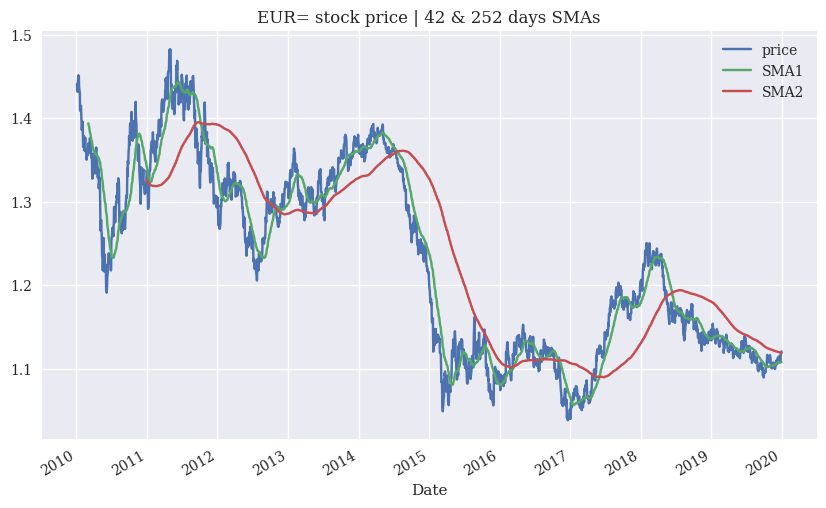

In [118]:
#generates a line plot of the data DataFrame with a specified title and figure size using the plot() function from pandas.
#data: the plot() function is called on it to generate the plot.
#title='EUR= stock price | 42 & 252 days SMAs': Sets the title of the plot to 'EUR= stock price | 42 & 252 days SMAs'.
#figsize=(10, 6): Specifies the size of the figure in inches. The resulting plot will have a width of 10 inches and a height of 6 inches.
#The plot() function in pandas is a wrapper around the matplotlib.pyplot.plot() function, which creates a line plot by default. 
#The DataFrame's index is used for the x-axis, and the column(s) of the DataFrame are used for the y-axis.

data.plot(title='EUR= stock price | 42 & 252 days SMAs',
          figsize=(10, 6));

## Strategy definition

we want to buy when the fast moving average crosses above the slower moving average and go short when the fast moving average crosses below the slow moving average
#we create a new column called 'position' and vetorize the comparisons, i.e. when the faster moving average is above the slower moving average a '1' is assigned 
#and if it's below then a '-1' is assigned

In [119]:
# setting the postion variable
data['position'] = np.where(data['SMA1'] > data['SMA2'],
                            1, -1)

In [122]:
#for the calculation of the fast moving average we need 42 data points and for the slower moving average we need 252 days of data points
#thus at the beginning of the data DataFrame SMA1 and SMA2 are empty
print(data.head())
print(data.tail())

             price  SMA1  SMA2  position
Date                                    
2010-01-04  1.4411   NaN   NaN        -1
2010-01-05  1.4368   NaN   NaN        -1
2010-01-06  1.4412   NaN   NaN        -1
2010-01-07  1.4318   NaN   NaN        -1
2010-01-08  1.4412   NaN   NaN        -1
             price      SMA1      SMA2  position
Date                                            
2019-12-24  1.1087  1.107698  1.119630        -1
2019-12-26  1.1096  1.107740  1.119529        -1
2019-12-27  1.1175  1.107924  1.119428        -1
2019-12-30  1.1197  1.108131  1.119333        -1
2019-12-31  1.1210  1.108279  1.119231        -1


In [123]:
#The following codes drops rows that have 'NaN' values, inplace=True modifies the dataframe directly
data.dropna(inplace=True)

In [124]:
#now there are only rows in the DataFrame where each cell has a number
data.head()

,price,SMA1,SMA2,position
Date,,,,
2010-12-31,1.3377,1.342579,1.326218,1
2011-01-03,1.3351,1.340945,1.325798,1
2011-01-04,1.3301,1.338940,1.325374,1
2011-01-05,1.3151,1.336448,1.324874,1
2011-01-06,1.3001,1.333995,1.324351,1


## Plot Position and dynamics
we see how to grafically explore when our strategy is executed or not

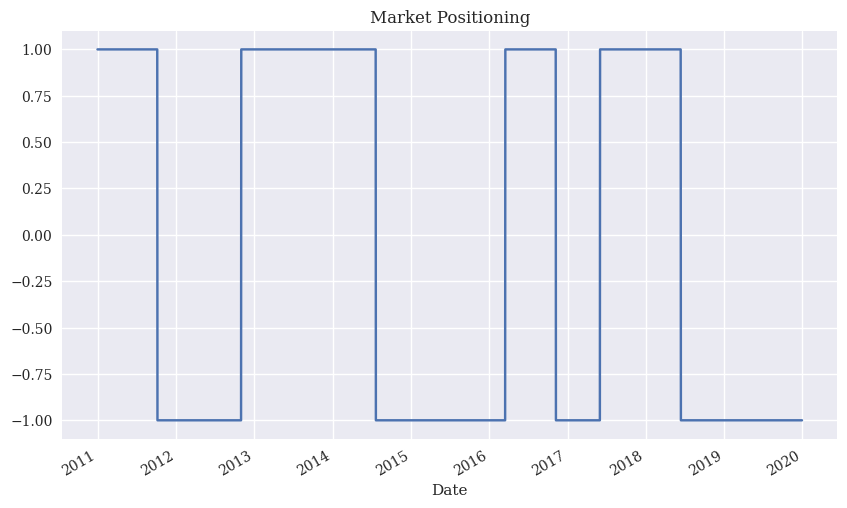

In [ ]:
#visualizes the position, i.e. if the trading strategy was long or short
#starts with long position

#plot(): The plot() function is called on the selected column to generate the plot.
#ylim=[-1.1, 1.1]: Sets the y-axis limits of the plot. The lower limit is -1.1, and the upper limit is 1.1. This restricts the range of values displayed on the y-axis.
data['position'].plot(ylim=[-1.1, 1.1],
                      title='Market Positioning',
                      figsize=(10, 6));

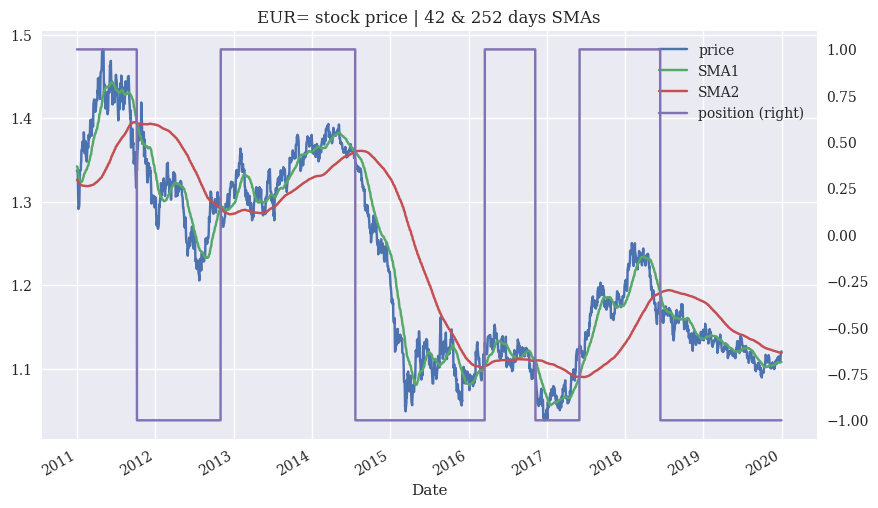

In [126]:
#overlays the previous graphs, i.e. the chart with the two simple moving averages and the positioning
#secondary_y='position': Specifies that the 'position' column should be plotted on a secondary y-axis. 
#The values of the 'position' column will be scaled and displayed on a separate y-axis on the right side of the plot.
data.plot(title='EUR= stock price | 42 & 252 days SMAs',
          figsize=(10, 6), secondary_y='position');

## Strategy Returns and benchmark considerations
every strategy is always studied on the returns, it is an error to only consider the price

In [127]:
#adds the new column 'returns' to the data DataFrame

#/ data['price'].shift(1): Divides the 'price' column by its lagged version, obtained by shifting the 'price' column by one position. 
#This calculates the ratio between the current price and the previous price.
#np.log(): Applies the natural logarithm function to the calculated ratio. Taking the logarithm of the price ratio allows us to compute the logarithmic returns.
data['returns'] = np.log(data['price'] / data['price'].shift(1))

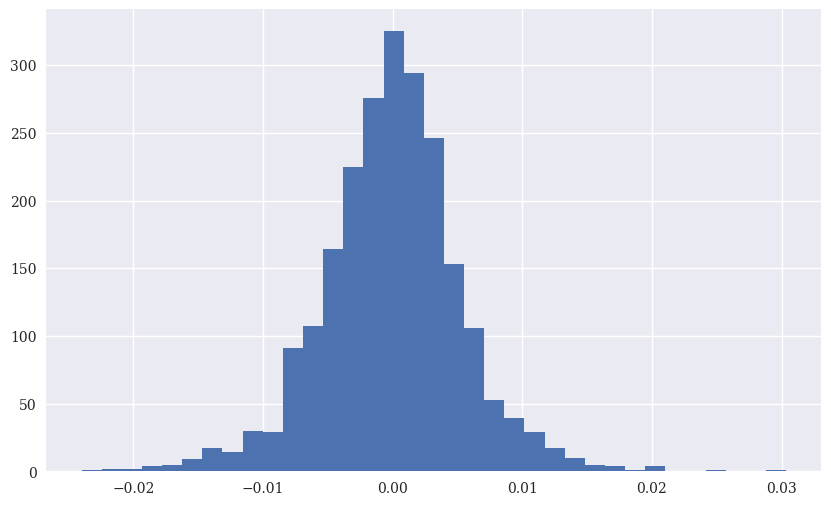

In [129]:
#### Histogram of the returns ####
#useful to see the shape of the ditribution of the returns

#bins=35: Specifies the number of bins to use in the histogram. In this case, the histogram will be divided into 35 equally spaced bins.
data['returns'].hist(bins=35, figsize=(10, 6));

In [ ]:
#### Calculates the strategy return ####

#we take the positions and multiply it with the returns
#we need to take into account that we derive the position based on today's SMA1 and SMA2
#we use today's close prices to update SMA1 and SMA2, which means we cannot take today's position calculated based on close prices to set up the return of the strategy for the whole day
#we could wait till the closing of the markets but the position derived from that would be the positioning of tomorrow, with the soonest being the opening price
#NB: sell means short (not just close the long position) if the market goes down 2% and position is -1 it means we are making the 2%
data['strategy'] = data['returns'] * data['position'].shift(1) 

In [133]:
#we calculate the sum of the log-returns, not a good economic measure yet but it is a good first indicator. Nevertheless we are still in log space
# based on the numbers the strategy seems to outperform but it's hard to interpret the numbers
data[['returns', 'strategy']].sum()

returns    -0.176731
strategy    0.253121
dtype: float64

In [ ]:
#now we apply the exponential function to leave the log-space and get back to real world returns
#in absolute numbers when we get started with $1 invested we end up in the passive benchmark investment with 83.8 cents and the strategy ends up with $1.288
#The code calculates the sum of the 'returns' and 'strategy' columns in the data DataFrame and applies the exponential function np.exp() to each sum. 
#This operation is performed using the sum() and apply() methods from pandas.

#data[['returns', 'strategy']]: Selects the 'returns' and 'strategy' columns from the data DataFrame by passing a list of column names as the indexer.
#sum(): Calculates the sum of each selected column. The sum() method aggregates the values within each column, adding them up.
#apply(np.exp): Applies the np.exp() function to each sum. The apply() method allows you to apply a given function to each element in the Series or DataFrame.
data[['returns', 'strategy']].sum().apply(np.exp)

returns     0.839637
strategy    1.290547
dtype: float64

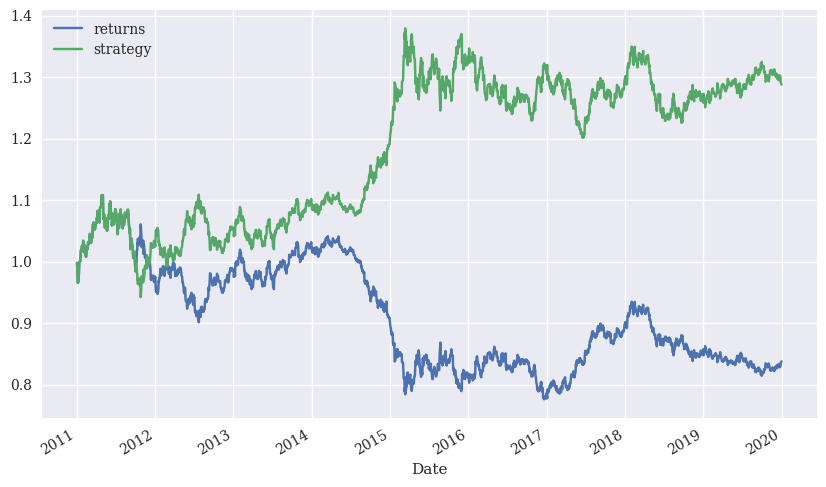

In [134]:
#The code data[['returns', 'strategy']].dropna().cumsum().apply(np.exp).plot(figsize=(10, 6)) generates a line plot 
#of the cumulative sum of the 'returns' and 'strategy' columns in the data DataFrame after dropping any rows with missing values. 
#The cumulative sums are then exponentiated using the np.exp() function before plotting. The resulting plot is displayed with a specified figure size.
#cumsum(): Calculates the cumulative sum of each column. The cumsum() method accumulates the values within each column, producing a running total.
#--> to the result the plot method is applied then
#since we start with a long position the green line is on top of the blue line, when positions diverge the two lines become separable
data[['returns', 'strategy']].dropna().cumsum(
            ).apply(np.exp).plot(figsize=(10, 6));

In [137]:
#Annualized return of the buy-and-hold as well as of the strategy
data[['returns', 'strategy']].mean() * 252

returns    -0.019671
strategy    0.028174
dtype: float64

In [138]:
#Annualized standard deviation
data[['returns', 'strategy']].std() * 252 ** 0.5

returns     0.085414
strategy    0.085405
dtype: float64

In [139]:
#creating a column with the cumsum().apply(np.exp) values
data['cumret'] = data['strategy'].cumsum().apply(np.exp)

In [140]:
#The code calculates the cumulative maximum of the 'cumret' column in the data DataFrame using the cummax() function from pandas. 
#It assigns the resulting cumulative maximum values to a new column named 'cummax' in the data DataFrame.
data['cummax'] = data['cumret'].cummax()

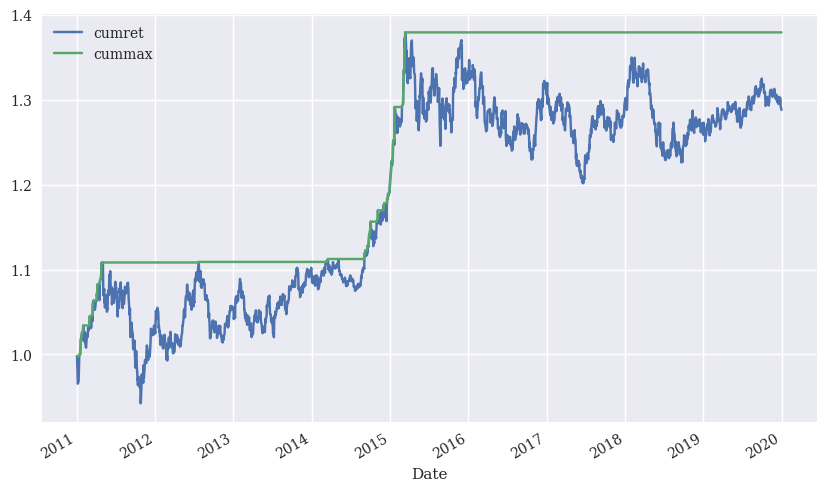

In [141]:
#Plotting the columns 'cumret' and 'cummax'
data[['cumret', 'cummax']].dropna().plot(figsize=(10, 6));

## Drawdowns

In the context of trading strategies, a drawdown refers to the decline in the value of an investment or trading account from its peak value to its lowest point before recovering. It represents the peak-to-trough decline experienced by an investment over a specific period.

Drawdown is often expressed as a percentage and is calculated as follows:
-Identify the peak value: Determine the highest value reached by the investment or trading account during the specified period.
-Identify the trough value: Determine the lowest value reached by the investment or trading account after the peak value.
-Calculate the drawdown: Calculate the percentage decline by subtracting the trough value from the peak value, dividing it by the peak value, and multiplying by 100.

Drawdown is an essential metric in evaluating the risk associated with a trading strategy. It provides insights into the potential losses an investor or trader may experience during unfavorable market conditions.

Maximum drawdown, specifically, represents the largest drawdown experienced by a trading strategy over a given period. It identifies the most significant percentage decline in the value of the investment or trading account from a peak to a subsequent trough. Maximum drawdown helps assess the historical downside risk associated with a trading strategy, providing an indication of its potential for large losses.

By monitoring drawdowns and maximum drawdowns, traders and investors can gain a better understanding of the risks involved and make informed decisions regarding position sizing, risk management, and overall strategy evaluation.

In [151]:
drawdown = data['cummax'] - data['cumret']

In [152]:
#Maximum drawdown in percentage points, i.e. 17.8%-points. This means if the peak was at 117.8% from the start the lowest point afterwards was at 100% again
drawdown.max()

0.17779367070195895

<Axes: xlabel='Date'>

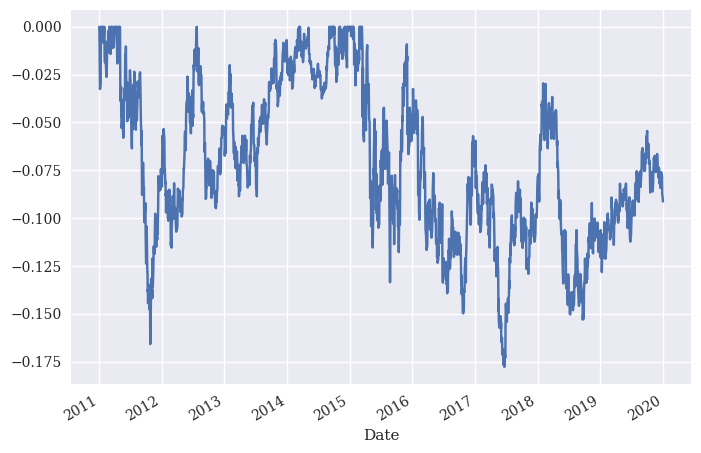

In [153]:
#Drawdown is normally always shown as a negative figure
drawdown=-1*drawdown
drawdown.plot()

## Strategies based on Momentum

### Getting into the Basics

In [78]:
#Based on the code above we extract the gold price which is called XAU
#The abbreviation of gold as "XAU" is derived from the standard currency codes used in international finance and trading. 
#These codes, known as ISO 4217 currency codes, are three-letter alphabetic codes that represent various currencies and precious metals.
#In the ISO 4217 standard, "X" is used as a prefix to represent "precious metals." Therefore, "XAU" specifically denotes "gold." 
#Similarly, other precious metals have their own ISO 4217 codes, such as "XAG" for silver, "XPT" for platinum, and "XPD" for palladium.

data = pd.DataFrame(raw['XAU='])

In [79]:
#The column name is renamed from XAU to price
data.rename(columns={'XAU=': 'price'}, inplace=True)

In [80]:
#log returns are calculated
data['returns'] = np.log(data['price'] / data['price'].shift(1))

In [81]:
#The NumPy function np.sign() is used to compute the element-wise sign of an array. 
#It returns an array with the same shape as the input array, where each element is replaced with -1, 0, or 1, depending on the sign of the corresponding element in the input array.
#This means if a value has -3 it will be replace with -1 with the np.sign function, if a value is 0 it stays zero and if a value is for example +7 it will be replaced by +1
data['position'] = np.sign(data['returns'])

In [82]:
#as for the SMA strategy the position is shifted again
#Idea behind this strategy is that if gold went up yesterday it will also go up today
data['strategy'] = data['position'].shift(1) * data['returns']

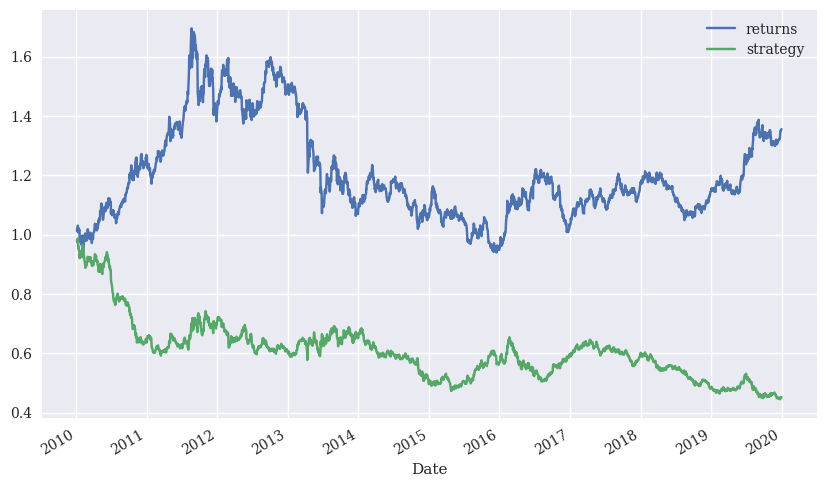

In [83]:
#as for the SMA strategy the log-returns are transformed into real-world returns and then plotted
data[['returns', 'strategy']].dropna().cumsum(
            ).apply(np.exp).plot(figsize=(10, 6));

In [84]:
#with adding rolling(3) it takes the average of the returns over 3 days and if that average is positive np.sign returns a +1, if the average is negative np.sign returns -1
data['position'] = np.sign(data['returns'].rolling(3).mean())

In [85]:
data.head()

,price,returns,position,strategy
Date,,,,
2010-01-04,1120.00,NaN,NaN,NaN
2010-01-05,1118.65,-0.001206,NaN,NaN
2010-01-06,1138.50,0.017589,NaN,-0.017589
2010-01-07,1131.90,-0.005814,1.0,-0.005814
2010-01-08,1136.10,0.003704,1.0,-0.003704


In [86]:
#again shifting the positions
data['strategy'] = data['position'].shift(1) * data['returns']

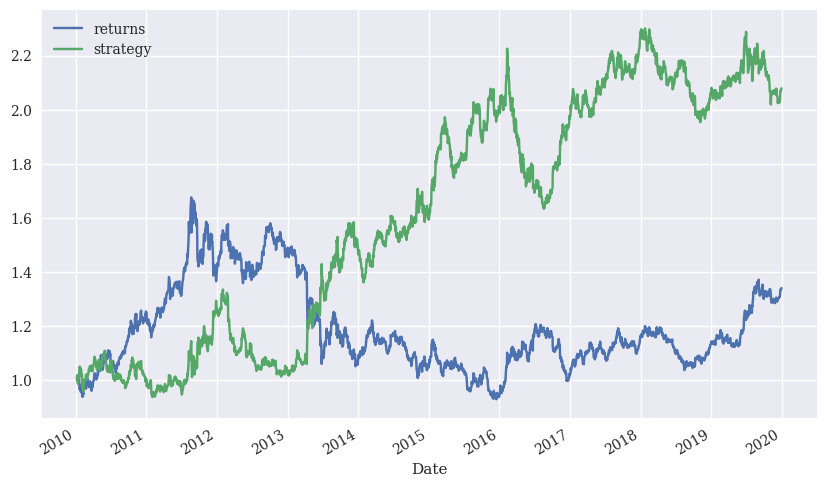

In [87]:
#again transforming log-returns to real-world returns and plotting the graph
data[['returns', 'strategy']].dropna().cumsum(
        ).apply(np.exp).plot(figsize=(10, 6));

Analysing if momentum works on intraday data

In [88]:
#fn = 'AAPL_1min_05052020.csv'
fn = 'SPX_1min_05052020.csv'

In [89]:
#The code data = pd.read_csv(fn, index_col=0, parse_dates=True) reads a CSV file and loads the data into a pandas DataFrame called data.
#pd.read_csv: This is a function provided by the pandas library that reads data from a CSV (Comma-Separated Values) file.
#fn: It represents the file name or the path to the CSV file you want to read.
#index_col=0: This parameter specifies that the first column of the CSV file should be used as the index column in the DataFrame. The values in this column will be used as row labels.
#parse_dates=True: This parameter instructs pandas to parse the dates in the CSV file as datetime objects. 
#If there are columns in the CSV file containing dates or timestamps, pandas will attempt to recognize and convert them to datetime format.
#-->CSV file specified by fn will be read, and the data will be stored in the data DataFrame. 
#The first column of the CSV file will be used as the index column, and if there are any date columns, they will be parsed as datetime objects.

data = pd.read_csv(fn, index_col=0, parse_dates=True)

In [90]:
#the data contains only 241 data points from 5 May 2020, i.e. 4 hours
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 241 entries, 2020-05-05 16:00:00 to 2020-05-05 20:00:00
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   HIGH    241 non-null    float64
 1   LOW     241 non-null    float64
 2   OPEN    241 non-null    float64
 3   CLOSE   241 non-null    float64
 4   COUNT   241 non-null    float64
dtypes: float64(5)
memory usage: 11.3 KB


In [91]:
#calculating the returns
data['returns'] = np.log(data['CLOSE'] /
                         data['CLOSE'].shift(1))

In [92]:
#creates the list to_plot
#is the benchmark performance
to_plot = ['returns']

In [93]:
#The provided code snippet implements a loop that iterates over a list of integers [1, 3, 5, 7, 9]. Within each iteration, it performs the following operations using the data DataFrame:

#data['position_%d' % m] = np.sign(data['returns'].rolling(m).mean()):
#--Calculates the rolling mean of the 'returns' column using a window of size m (1, 3, 5, 7, or 9).
#--Applies the np.sign() function to determine the sign (positive, negative, or zero) of each rolling mean value.
#--Assigns the resulting sign values to a new column in the DataFrame, where the column name includes the value of m. For example, if m = 1, the column name will be 'position_1'.

#data['strategy_%d' % m] = (data['position_%d' % m].shift(1) * data['returns']):
#--Shifts the values in the 'position_%d' column (created in the previous step) by one position, effectively aligning the position signals for the previous day.
#--Multiplies the shifted position values with the 'returns' column, which represents the logarithmic returns of the data.
#--Assigns the resulting values to a new column in the DataFrame, where the column name includes the value of m. For example, if m = 1, the column name will be 'strategy_1'.

#to_plot.append('strategy_%d' % m):
#--Appends the name of the newly created 'strategy_%d' column (based on the value of m) to the to_plot list.
#--By executing this code, the DataFrame data will have additional columns representing the position signals and strategy returns for different rolling windows. 
#The to_plot list will contain the names of the strategy columns, which can be used for visualization or further analysis.

for m in [1, 3, 5, 7, 9]:
    data['position_%d' % m] = np.sign(data['returns'].rolling(m).mean())
    data['strategy_%d' % m] = (data['position_%d' % m].shift(1) *
                               data['returns'])
    to_plot.append('strategy_%d' % m)

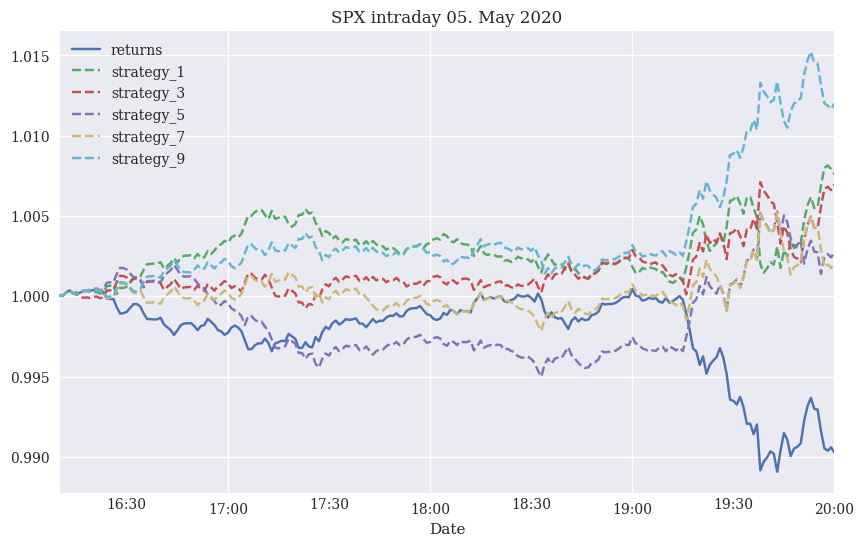

In [94]:
#The provided code is plotting the cumulative returns of the strategies stored in the DataFrame data.
#data[to_plot]: This selects the columns in the DataFrame data specified by the to_plot list. These columns correspond to the strategy returns for different rolling windows.

data[to_plot].dropna().cumsum().apply(np.exp).plot(
    title='SPX intraday 05. May 2020',
    figsize=(10, 6), style=['-', '--', '--', '--', '--', '--']);

## Strategies based on Mean-Reversion

### Getting into the Basics

Idea behind mean-reversion is that whenever a price moves away too far from what the assumed mean is, then we expected that the price returns to the mean sometime soon. We have an idea about the distance and an idea about the time when it will return to the mean. 

In [6]:
import numpy as np
import pandas as pd
from pylab import mpl, plt

In [8]:
raw = pd.read_csv('http://hilpisch.com/pyalgo_eikon_eod_data.csv',
                   index_col=0, parse_dates=True).dropna()
data = pd.DataFrame(raw['GDX'])

In [9]:
data.rename(columns={'GDX': 'price'}, inplace=True)

In [10]:
data['returns'] = np.log(data['price'] /
                         data['price'].shift(1))

In [11]:
#as a mean the 25-day simple moving average is taken
#stocks are generally assumed to trend
#currencies, gold, volatiliy are normally mean-reverting
#question is always what exactly is the mean
SMA = 60

In [12]:
data['SMA'] = data['price'].rolling(SMA).mean()

In [13]:
#notion of distance, threshold for distance in terms of the price
threshold = 9.0

In [14]:
data['distance'] = data['price'] - data['SMA']

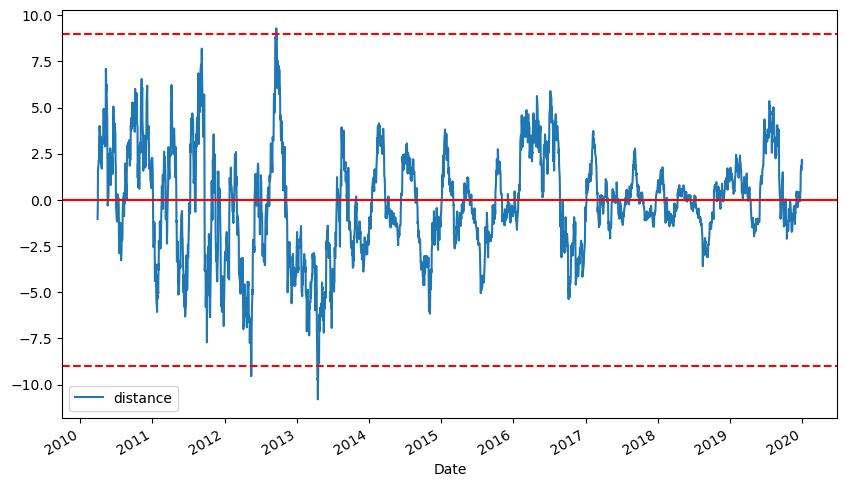

In [15]:
#The provided code is plotting the 'distance' column of the DataFrame data and adding three horizontal lines to the plot. 

#data['distance'].dropna().plot(figsize=(10, 6), legend=True): 
#--This line plots the values in the 'distance' column of the DataFrame data after removing any rows with missing values (NaNs). 
#--The figsize=(10, 6) parameter sets the size of the plot figure, and legend=True displays the legend on the plot.

#plt.axhline(threshold, color='r', ls='--'): 
#--This line adds a horizontal line to the plot at the threshold value. 
#--The color='r' parameter sets the line color to red, and ls='--' makes the line dashed.

#plt.axhline(-threshold, color='r', ls='--'): 
#--This line adds another horizontal line to the plot at the negative value of threshold, also with a red color and dashed style.

#plt.axhline(0, color='r'): 
#--This line adds a horizontal line at the value of 0, representing the x-axis or the baseline. The line color is set to red.

data['distance'].dropna().plot(figsize=(10, 6), legend=True)
plt.axhline(threshold, color='r', ls='--')
plt.axhline(-threshold, color='r', ls='--')
plt.axhline(0, color='r');

In [16]:
#when the distance, i.e. the price, is above the upper threshold we would go short with the expectation that the price will return to the mean
data['position'] = np.where(data['distance'] > threshold,
                            -1, np.nan)

In [17]:
#when the distance, i.e. the price, is below the lower threshold we would go long with the expectation that the price will return to the mean
data['position'] = np.where(data['distance'] < -threshold,
                            1, data['position'])

In [18]:
#Contrary to the other two strategies we are also neutral in this strategy, i.e. we can be long, short or neutral. The question is when are we neutral?
#When the 'distance' changes from negative to positive or from positive to negative we put in a 0, i.e. we become neutral
#so: whenever there is a change in the sign from + to - or from -to +
data['position'] = np.where(data['distance'] *
            data['distance'].shift(1) < 0, 0, data['position'])

In [19]:
#positions are still not filled up to the neutrals which we take care of here
#for filling up the positions till there is trade signal we use forward fill, i.e. the ffill() method since we stay long till there is a change in the sign of distance
#This method fills any remaining missing values with 0. It replaces any remaining NaNs with the specified value of 0.
data['position'] = data['position'].ffill().fillna(0)

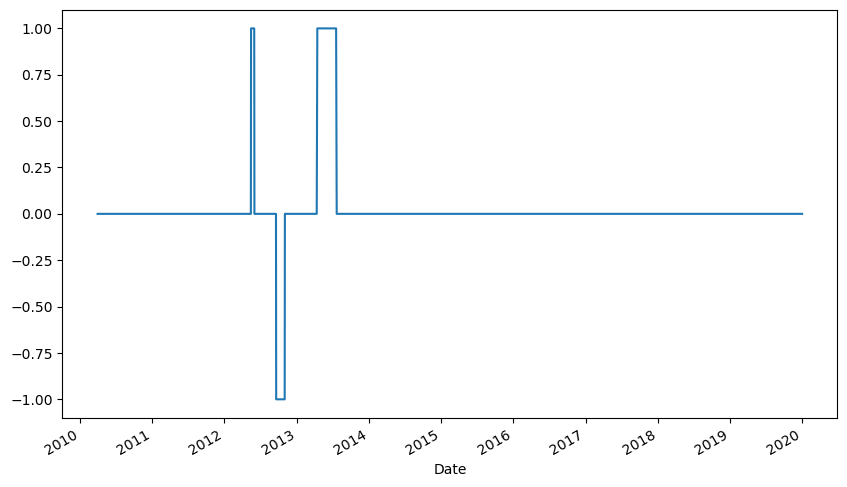

In [20]:
#This is how the strategy looks like in terms of +1, 0 and -1
#what we see here is that we have long stretches of being market neutral, i.e. without being neither long nor short, because neither the upper nor the lower threshold was hit
data['position'].iloc[SMA:].plot(ylim=[-1.1, 1.1],
                               figsize=(10, 6));

In [21]:
#backtest is formally the same as we had before
data['strategy'] = data['position'].shift(1) * data['returns']

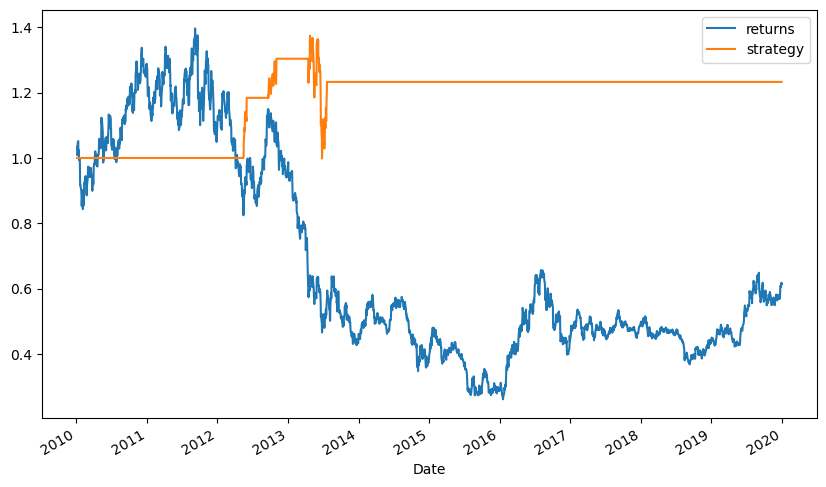

In [22]:
data[['returns', 'strategy']].dropna().cumsum(
        ).apply(np.exp).plot(figsize=(10, 6));